This Jupyter notebook performs the tasks:
- Perform k-NN analysis and figure plots
- Create the base dataset which will be used for Logistic Regression and k-NN with cyclic encoding.

In [175]:
import pandas as pd
from pathlib import Path
import numpy as np

OUTPUT_DIR = Path("avalanche_dataset")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_CSV = OUTPUT_DIR / f"warnings_winter_2023_2026_DIST.csv"
OUTPUT_CSV_uni = OUTPUT_DIR / f"warnings_winter_2023_2026_DIST_uni.csv"
OUTPUT_CSV_multi = OUTPUT_DIR / f"warnings_winter_2023_2026_DIST_multi.csv"

df = pd.read_csv("avalanche_dataset\warnings_winter_2023_2026.csv")

<>:11: SyntaxWarning: invalid escape sequence '\w'
<>:11: SyntaxWarning: invalid escape sequence '\w'
C:\Users\alexi\AppData\Local\Temp\ipykernel_30552\1041357638.py:11: SyntaxWarning: invalid escape sequence '\w'
  df = pd.read_csv("avalanche_dataset\warnings_winter_2023_2026.csv")


In [ ]:
#Cyclic transformation
def col_to_sine_cosine(df, col, period):
    df[f"{col}_sin"] = np.sin(2 * np.pi * df[col] / period)
    df[f"{col}_cos"] = np.cos(2 * np.pi * df[col] / period)
    df.drop(columns=[col], inplace=True)

In [177]:
# Identify numeric and categorical predictor columns.
numeric_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(exclude="number").columns.tolist()

print("Numeric columns to standardize:", numeric_cols)
print("Categorical columns to encode:", categorical_cols)

Numeric columns to standardize: ['publish_hour', 'publish_month', 'rainfall_most_exposed_area', 'rainfall_average', 'wind_direction_change', 'wind_shift_start', 'wind_shift_end', 'temperature_min', 'temperature_max', 'freezing_level_masl', 'freezing_level_start', 'freezing_level_end', 'rain_snow_line_altitude_masl', 'rain_snow_line_start', 'rain_snow_line_end']
Categorical columns to encode: ['RegionName', 'geographical_region', 'risk', 'cloud_cover', 'wind_speed', 'wind_shift_speed', 'wind_direction', 'wind_shift_direction']


In [ ]:
cyclic_cols = ['publish_hour', 'publish_month','wind_shift_start', 'wind_shift_end','freezing_level_start', 'freezing_level_end', 'rain_snow_line_start', 'rain_snow_line_end' ]

for cyclic_col in cyclic_cols:
    numeric_cols.remove(cyclic_col)

categorical_cols.remove("risk")

print("Numeric columns to standardize:", numeric_cols)
print("Categorical columns to encode:", categorical_cols)
print("Cyclic columns to transform:", cyclic_cols)

Numeric columns to standardize: ['rainfall_most_exposed_area', 'rainfall_average', 'wind_direction_change', 'temperature_min', 'temperature_max', 'freezing_level_masl', 'rain_snow_line_altitude_masl']
Categorical columns to encode: ['RegionName', 'geographical_region', 'cloud_cover', 'wind_speed', 'wind_shift_speed', 'wind_direction', 'wind_shift_direction']
Cyclic columns to transform: ['publish_hour', 'publish_month', 'wind_shift_start', 'wind_shift_end', 'freezing_level_start', 'freezing_level_end', 'rain_snow_line_start', 'rain_snow_line_end']


In [179]:
#Convert cyclic columns
for col in cyclic_cols:
    period = 12 if col == "publish_month" else 24
    col_to_sine_cosine(df, col, period)

In [180]:
print(df.head())
df.to_csv(OUTPUT_CSV, index=False, encoding="utf-8-sig")
print("\nSaved!")

     RegionName geographical_region  risk cloud_cover  \
0  Svalbard øst   Svalbard / Arctic  High   Not given   
1  Svalbard øst   Svalbard / Arctic  High   Not given   
2  Svalbard øst   Svalbard / Arctic  High   Not given   
3  Svalbard øst   Svalbard / Arctic  High   Not given   
4  Svalbard øst   Svalbard / Arctic  High      Cloudy   

   rainfall_most_exposed_area  rainfall_average   wind_speed wind_shift_speed  \
0                         0.0               0.0      No Wind          No Wind   
1                         0.0               0.0      No Wind          No Wind   
2                         0.0               0.0      No Wind          No Wind   
3                         0.0               0.0      No Wind          No Wind   
4                        40.0              20.0  Strong gale    Moderate gale   

  wind_direction wind_shift_direction  ...  wind_shift_end_sin  \
0        No Wind              No Wind  ...        0.000000e+00   
1        No Wind              No Wind 

In [ ]:
#Univariate and multivariate filters applied to the dataset
univariate_vars = [
    "rainfall_most_exposed_area",
    "rainfall_average",
    "wind_shift_speed",
    "wind_speed",
    "publish_month_sin",
    "publish_month_cos",
    "temperature_max",
    "temperature_min",
    "cloud_cover"
]

multivariate_vars = [
    "rainfall_most_exposed_area",
    "rainfall_average",
    "wind_shift_speed",
    "wind_speed",
    "publish_month_sin",
    "publish_month_cos",
    "temperature_max",
    "cloud_cover",
    "publish_hour_sin",
    "publish_hour_cos",
]

df_uni = df[univariate_vars+ ["risk"]]
df_multi = df[multivariate_vars+ ["risk"]]

df_uni.to_csv(OUTPUT_CSV_uni, index=False, encoding="utf-8-sig")
print("\n Uni Saved!")

df_multi.to_csv(OUTPUT_CSV_multi, index=False, encoding="utf-8-sig")
print("\nMulti Saved!")


   rainfall_most_exposed_area  rainfall_average wind_shift_speed   wind_speed  \
0                         0.0               0.0          No Wind      No Wind   
1                         0.0               0.0          No Wind      No Wind   
2                         0.0               0.0          No Wind      No Wind   
3                         0.0               0.0          No Wind      No Wind   
4                        40.0              20.0    Moderate gale  Strong gale   

   publish_month_sin  publish_month_cos  temperature_max  temperature_min  \
0      -5.000000e-01           0.866025              0.0              0.0   
1      -5.000000e-01           0.866025              0.0              0.0   
2      -5.000000e-01           0.866025              0.0              0.0   
3      -5.000000e-01           0.866025              0.0              0.0   
4      -2.449294e-16           1.000000             -6.0            -11.0   

  cloud_cover  risk  
0   Not given  High  
1   No

In [ ]:
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    cohen_kappa_score,
    roc_auc_score,
    confusion_matrix,
    precision_score
)

In [ ]:
#Pipeline: 10-fold cross-validation + encoding categorical variables + standardizing numerical features

cyclic_feature_cols = [f"{c}_{s}" for c in cyclic_cols for s in ("sin", "cos")]
categorical_pipeline = Pipeline([("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([
    ("categorical", categorical_pipeline, categorical_cols),
    ("numeric", StandardScaler(), numeric_cols),
    ("cyclic", "passthrough", cyclic_feature_cols),
])
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

In [ ]:
#Applies k-NN to any dataframe

def apply_knn(df, output_file):
    numeric_cols = df.select_dtypes(include="number").columns.tolist()
    categorical_cols = df.select_dtypes(exclude="number").columns.tolist()
    categorical_cols.remove("risk")

    #Select cyclic columns that are actually in the filter
    cyclic_feature_cols = []
    for c in [f"{c}_{s}" for c in cyclic_cols for s in ("sin", "cos")]:
        if c in numeric_cols:
            numeric_cols.remove(c)
            cyclic_feature_cols.append(c)

    #Same pipeline as before
    preprocessor = ColumnTransformer([
        ("categorical", Pipeline([("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_cols),
        ("numeric", StandardScaler(), numeric_cols),
        ("cyclic", "passthrough", cyclic_feature_cols),
    ])
    cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

    risk_order = ["High", "Medium", "Low"] # for confusion matrix
    
    X = df.drop("risk", axis="columns")
    y = df["risk"]
    classes = np.sort(y.unique())  # predict_proba column order
    Y_onehot = (y.to_numpy()[:, None] == classes).astype(float)

    #apply k-NN to obtain metrics for each value of k
    results = []
    for k in range(1, 32, 2):
        model = Pipeline([("preprocessor", preprocessor), ("knn", KNeighborsClassifier(n_neighbors=k))])
        proba = cross_val_predict(model, X, y, cv=cv, method="predict_proba", n_jobs=-1)
        pred = classes[proba.argmax(axis=1)]

        high, medium, low = recall_score(y, pred, labels=risk_order, average=None, zero_division=0)
        cm = confusion_matrix(y, pred, labels=risk_order)   # rows true, cols predicted: 0=High, 1=Medium, 2=Low

        #if k==3:
        #    print(cm)

        results.append({
            "k": k,
            "accuracy": 100 * accuracy_score(y, pred),
            "kappa": cohen_kappa_score(y, pred),
            "kappa_quad": cohen_kappa_score(y, pred, weights="quadratic", labels=risk_order),
            "precision": precision_score(y, pred, average="weighted", zero_division=0),
            "recall": recall_score(y, pred, average="weighted", zero_division=0),
            "f1": f1_score(y, pred, average="weighted", zero_division=0),
            "auc": roc_auc_score(y, proba, labels=classes, multi_class="ovr", average="weighted"),
            "rmse": np.sqrt(np.mean((proba - Y_onehot) ** 2)),
            "recall_high": high,
            "recall_medium": medium,
            "recall_low": low,
            "high_to_low_pct": 100 * cm[0, 2] / cm[0].sum(),
            "medium_to_low_pct": 100 * cm[1, 2] / cm[1].sum(),
            "low_to_high_pct": 100 * cm[2, 0] / cm[2].sum(),
        })

    results_df = pd.DataFrame(results)
    print(results_df.round(4).to_string(index=False))
    results_df.to_csv(output_file, index=False)
    return results_df

In [ ]:
res_all   = apply_knn(df,"knn_all.csv")

[[1694  972   70]
 [ 837 5196  882]
 [ 147 1104 2288]]
 k  accuracy  kappa  kappa_quad  precision  recall     f1    auc   rmse  recall_high  recall_medium  recall_low  high_to_low_pct  medium_to_low_pct  low_to_high_pct
 1   69.1130 0.4921      0.6194     0.6907  0.6911 0.6909 0.7375 0.4538       0.6404         0.7268      0.6606           3.6184            15.8062           3.1365
 3   69.5830 0.4955      0.6154     0.6953  0.6958 0.6949 0.8011 0.3843       0.6192         0.7514      0.6465           2.5585            12.7549           4.1537
 5   69.7801 0.4947      0.6186     0.6968  0.6978 0.6959 0.8169 0.3719       0.5888         0.7636      0.6536           3.3626            14.2299           2.5713
 7   70.3412 0.4980      0.6272     0.7044  0.7034 0.7002 0.8198 0.3697       0.5603         0.7879      0.6491           3.2164            13.5069           1.2433
 9   70.1971 0.4914      0.6199     0.7046  0.7020 0.6974 0.8201 0.3697       0.5329         0.8019      0.6375         

In [ ]:
res_uni   = apply_knn(df_uni, "knn_uni.csv")

 k  accuracy  kappa  kappa_quad  precision  recall     f1    auc   rmse  recall_high  recall_medium  recall_low  high_to_low_pct  medium_to_low_pct  low_to_high_pct
 1   61.4329 0.3664      0.5158     0.6140  0.6143 0.6141 0.6733 0.5071       0.5731         0.6586      0.5598           5.5921            20.2314           4.2385
 3   63.7680 0.4019      0.5311     0.6369  0.6377 0.6368 0.7517 0.4170       0.5917         0.6954      0.5603           3.7281            16.3268           6.2447
 5   64.7915 0.4141      0.5455     0.6463  0.6479 0.6464 0.7727 0.3989       0.5614         0.7132      0.5872           5.3363            17.3680           3.6168
 7   66.1031 0.4284      0.5684     0.6602  0.6610 0.6580 0.7804 0.3924       0.5384         0.7449      0.5920           4.0205            15.9942           2.1758
 9   66.5883 0.4329      0.5731     0.6657  0.6659 0.6620 0.7861 0.3885       0.5325         0.7611      0.5829           3.3626            15.0687           2.0627
11   66.81

In [ ]:
res_multi = apply_knn(df_multi, "knn_multi.csv")

 k  accuracy  kappa  kappa_quad  precision  recall     f1    auc   rmse  recall_high  recall_medium  recall_low  high_to_low_pct  medium_to_low_pct  low_to_high_pct
 1   61.5466 0.3651      0.5207     0.6143  0.6155 0.6147 0.6716 0.5063       0.5742         0.6677      0.5454           4.9342            19.5662           3.7016
 3   63.8438 0.3975      0.5334     0.6366  0.6384 0.6363 0.7460 0.4181       0.5870         0.7121      0.5343           3.3260            15.6327           5.2275
 5   65.1706 0.4179      0.5574     0.6502  0.6517 0.6498 0.7683 0.4002       0.5746         0.7226      0.5728           3.8012            17.3102           3.4190
 7   65.8453 0.4217      0.5661     0.6584  0.6585 0.6551 0.7762 0.3939       0.5420         0.7492      0.5711           3.5088            16.3268           2.0627
 9   66.3685 0.4277      0.5732     0.6641  0.6637 0.6595 0.7823 0.3901       0.5369         0.7631      0.5674           2.7412            15.2133           1.9780
11   66.99

Plots

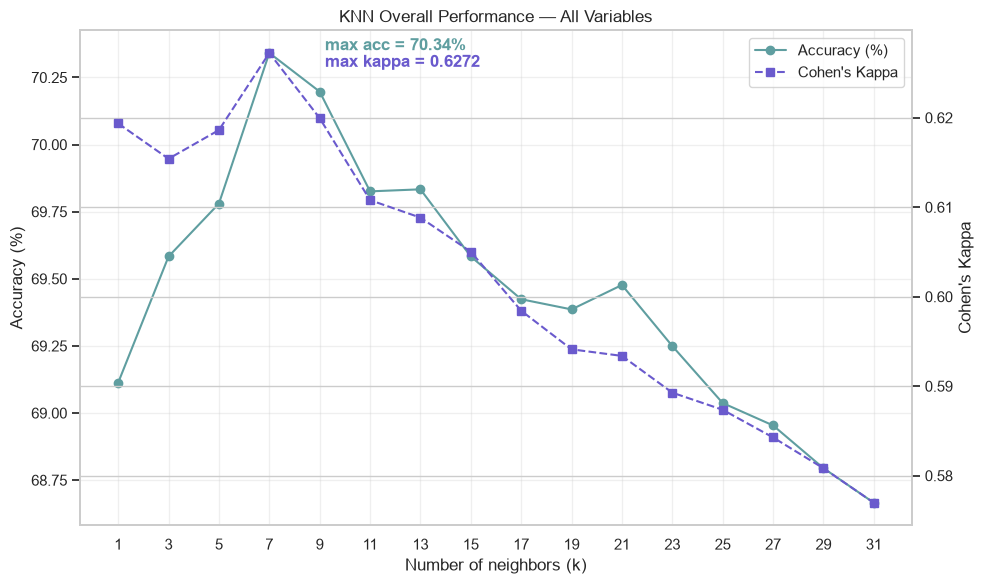

In [232]:
fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(
    res_all["k"], res_all["accuracy"],
    marker="o", label="Accuracy (%)", color="cadetblue"
)
ax1.set_xlabel("Number of neighbors (k)")
ax1.set_ylabel("Accuracy (%)")
ax1.set_xticks(res_all["k"])
ax1.grid(True, alpha=0.3)

best_acc = res_all.loc[res_all["accuracy"].idxmax()]
ax1.annotate(
    f"max acc = {best_acc['accuracy']:.2f}%",
    xy=(best_acc["k"], best_acc["accuracy"]),
    xytext=(40, 2), textcoords="offset points",
    color="cadetblue", fontweight="bold"
)

# Second axis for Cohen's Kappa
ax2 = ax1.twinx()
ax2.plot(
    res_all["k"], res_all["kappa_quad"],
    marker="s", linestyle="--", color="slateblue",
    label="Cohen's Kappa"
)
ax2.set_ylabel("Cohen's Kappa")

best_kappa = res_all.loc[res_all["kappa_quad"].idxmax()]
ax2.annotate(
    f"max kappa = {best_kappa['kappa_quad']:.4f}",
    xy=(best_kappa["k"], best_kappa["kappa_quad"]),
    xytext=(40, -10), textcoords="offset points",
    color="slateblue", fontweight="bold"
)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.title("KNN Overall Performance — All Variables")
fig.tight_layout()
plt.savefig("knn_all_performance.png", dpi=300, bbox_inches="tight")
plt.show()

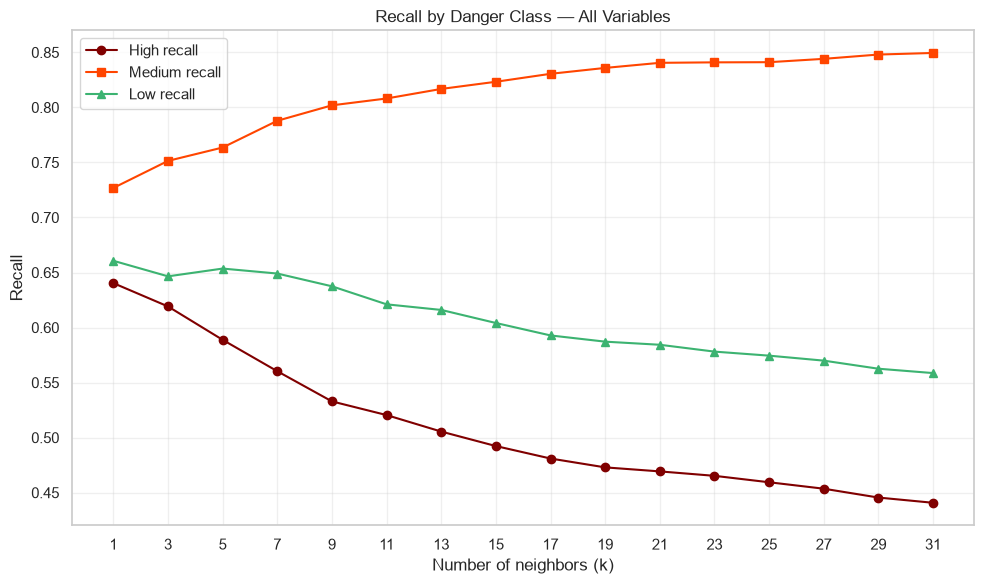

In [227]:
plt.figure(figsize=(10, 6))

plt.plot(
    res_all["k"], res_all["recall_high"],
    marker="o", label="High recall", color="maroon"
)
plt.plot(
    res_all["k"], res_all["recall_medium"],
    marker="s", label="Medium recall", color="orangered"
)
plt.plot(
    res_all["k"], res_all["recall_low"],
    marker="^", label="Low recall", color="mediumseagreen"
)

plt.xlabel("Number of neighbors (k)")
plt.ylabel("Recall")                      
plt.title("Recall by Danger Class — All Variables")
plt.xticks(res_all["k"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("knn_all_class_recall.png", dpi=300, bbox_inches="tight")
plt.show()

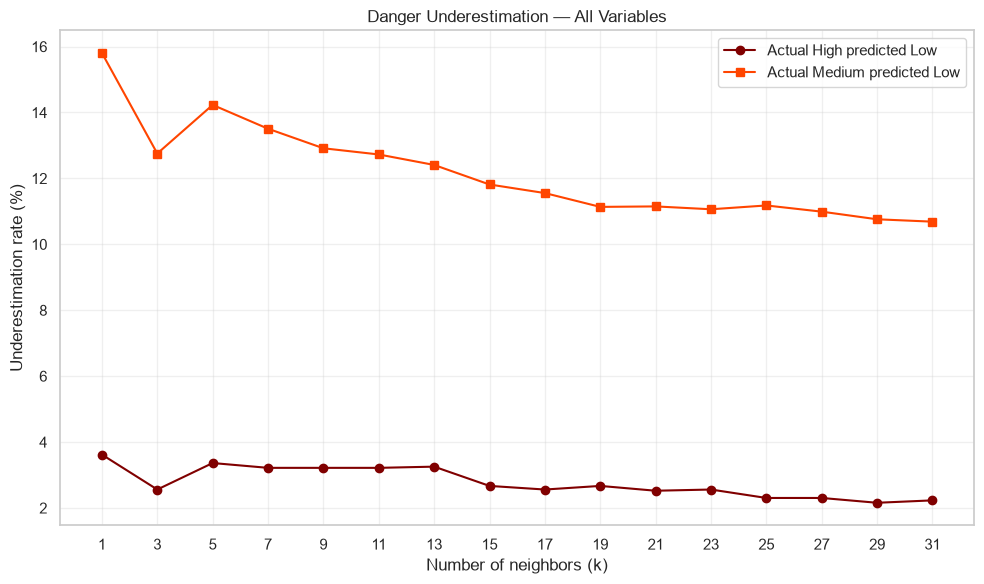

In [ ]:

plt.figure(figsize=(10, 6))

plt.plot(
    res_all["k"], res_all["high_to_low_pct"],
    marker="o", label="Actual High predicted Low", color="maroon"
)
plt.plot(
    res_all["k"], res_all["medium_to_low_pct"],
    marker="s", label="Actual Medium predicted Low", color="orangered"
)

plt.xlabel("Number of neighbors (k)")
plt.ylabel("Underestimation rate (%)")
plt.title("Danger Underestimation — All Variables")
plt.xticks(res_all["k"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("knn_all_underestimation.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
#Performed Wrapper feature selection on Weka to obtain the CSV
df_wrapper = pd.read_csv("avalanche_dataset\warnings_winter_2023_2026_wrapper_3NN.csv")
res_wrapper  = apply_knn(df_wrapper, "knn_wrapper.csv")

<>:1: SyntaxWarning: invalid escape sequence '\w'
<>:1: SyntaxWarning: invalid escape sequence '\w'
C:\Users\alexi\AppData\Local\Temp\ipykernel_30552\1634619290.py:1: SyntaxWarning: invalid escape sequence '\w'
  df_wrapper = pd.read_csv("avalanche_dataset\warnings_winter_2023_2026_wrapper_3NN.csv")


 k  accuracy  kappa  kappa_quad  precision  recall     f1    auc   rmse  recall_high  recall_medium  recall_low  high_to_low_pct  medium_to_low_pct  low_to_high_pct
 1   67.2782 0.4643      0.6021     0.6743  0.6728 0.6730 0.7237 0.4671       0.6188         0.6975      0.6663           5.4459            19.2046           1.8932
 3   67.9227 0.4716      0.5983     0.6785  0.6792 0.6788 0.7827 0.4031       0.6093         0.7210      0.6516           3.7281            15.7195           3.8429
 5   68.4761 0.4784      0.6102     0.6843  0.6848 0.6839 0.7990 0.3883       0.5932         0.7294      0.6683           3.9839            16.8330           2.4866
 7   68.2563 0.4703      0.6031     0.6818  0.6826 0.6810 0.8051 0.3830       0.5808         0.7442      0.6409           3.9474            15.8930           2.1758
 9   68.6884 0.4723      0.6000     0.6862  0.6869 0.6840 0.8066 0.3808       0.5581         0.7682      0.6276           3.7646            14.0998           2.1758
11   68.46

In [1]:
#Combine the results for all feature selection combinations for k=3
all = res_all.iloc[[1]]
uni = res_uni.iloc[[1]]
multi = res_multi.iloc[[1]]
wrapper  = res_wrapper.iloc[[1]]

knn_3 = pd.concat([all, uni, multi, wrapper], ignore_index=True)
knn_3.to_csv("3-nn.csv", index=False)

NameError: name 'res_all' is not defined